# 1. 이안류 CCTV 데이터셋
AI Hub의 '이안류 CCTV 데이터'는 우리나라 주요 해수욕장(해운대, 송정, 대천, 중문, 낙산)에서 이안류 발생 여부와 위치를 모니터링하기 위해 구축된 인공지능 학습용 데이터셋입니다. 해수욕장 주변에 설치된 CCTV 영상을 이미지로 변환하여, 이안류 발생 여부와 위치를 가시화하는 모델 개발에 활용할 수 있습니다. 이 데이터셋은 이안류 탐지 및 예측 시스템 개발에 필수적인 자료를 제공하며, 해수욕객의 안전을 위한 응용 서비스 구성에 활용될 수 있습니다. ​이안류는 해안에서 먼 바다로 빠르게 이동하는 폭이 좁은 바닷물의 흐름으로, 기상 상태가 양호한 경우에도 나타나며, 얕은 곳에 있던 해수욕객을 순식간에 수심이 깊은 먼 바다로 이동시켜 인명사고를 유발할 수 있습니다. 따라서 이러한 데이터셋은 해수욕장 안전 관리 및 이안류 예측 모델 개발에 중요한 역할을 합니다.

In [1]:
import json
import random
import shutil
import zipfile
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
from ultralytics import YOLO

# 실행 환경과 Ultralytics 설치 상태를 간단히 확인합니다.
import ultralytics
ultralytics.checks()

Ultralytics 8.4.171  Python-3.14.7 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
Setup complete  (24 CPUs, 23.7 GB RAM, 256.9/952.4 GB disk)


In [2]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [4]:
BASE_DIR = Path("./data").resolve()
ZIP_PATH = BASE_DIR / "ripcurrent.zip"
SAMPLE_DIR = BASE_DIR / "Sample"

SOURCE_IMAGE_DIR = SAMPLE_DIR / "01.원천데이터"
SOURCE_LABEL_DIR = SAMPLE_DIR / "02.라벨링데이터"

PROJECT_DIR = BASE_DIR / "ripcurrent"

TRAIN_DIR = PROJECT_DIR / "train"
VAL_DIR = PROJECT_DIR / "valid"
TEST_DIR = PROJECT_DIR / "test"

DATA_YAML = PROJECT_DIR / "ripcurrent.yaml"

In [25]:
MODEL_NAME = "yolo11s.pt"
IMAGE_SIZE = 640
EPOCHS = 50
PATIENCE = 10

BATCH_SIZE = 8
WORKERS = 0

TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1

CLASS_NAMES = {0: "rip_current"}

print('Current Working Directory: ', Path.cwd())
print('BASE_DIR: ', BASE_DIR)
print('PROJECT_DIR: ', PROJECT_DIR)
print('Model: ', MODEL_NAME)
print('device: ', DEVICE)
print('batch size: ', BATCH_SIZE)

Current Working Directory:  c:\DEV\AIML\4_MULTIMODAL
BASE_DIR:  C:\DEV\AIML\4_MULTIMODAL\data
PROJECT_DIR:  C:\DEV\AIML\4_MULTIMODAL\data\ripcurrent
Model:  yolo11s.pt
device:  cuda
batch size:  8


In [6]:
if SOURCE_IMAGE_DIR.exists() and SOURCE_LABEL_DIR.exists():
    print("이미 압축 해제된 데이터가 있습니다.")
else:
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f"압축 파일을 찾을 수 없습니다: {ZIP_PATH}\n"
                                "BASE_DIR 또는 ZIP_PATH를 확인하세요.")

    # 압축 풀기
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(BASE_DIR)
    print('압축 해제 완료')

이미 압축 해제된 데이터가 있습니다.


# 2. JSON Boudning Box > YOLO Bounding Box

- 원본 JSON의 drawing에는 객체를 둘러싼 사각형의 점 좌표가 들어있음
- YOLO의 일반적인 객체 탐지 라벨 형식
    - class_id  x_center  y_center  width  height  (네 개의 좌표를 모두 0 ~ 1 사이로 정규화)

```
- x_min: 객체의 가장 왼쪽 x
- y_min: 객체의 가장 위쪽 y
- x_max: 객체의 가장 오른쪽 x
- y_max: 객체의 가장 아래쪽 y
```

In [7]:
def polygon_to_yolo_bbox(points, image_width, image_height):
    """
    points: list [[x1, y1], [x2, y2], ...] JSON 사각형 점 좌표
    image_width: int 원본 이미지 너비
    image_height: int 원본 이미지 높이
    """
    # 좌표가 없을시 None return
    if not points or len(points) < 2:
        return None

    # YOLO 형식으로 변환
    xs = [float(point[0]) for point in points]  # x point들만 저장
    ys = [float(point[1]) for point in points]  # y point들만 저장

    # 네 점 중 가장 왼쪽/오른쪽/위/아래 좌표 구함
    x_min = max(0.0, min(xs))  # x point들 중 가장 작은 값 (가장 왼쪽)
    y_min = max(0.0, min(ys))  # y point들 중 가장 작은 값 (가장 아래)
    x_max = min(float(image_width), max(xs))  # x point들 중 가장 큰 값 (이미지 밖으로 튀어나가면 자름)
    y_max = min(float(image_height), max(ys))  # y point들 중 가장 큰 값 (이미지 밖으로 튀어나가면 자름)

    box_width = x_max - x_min  # Bounding box 너비
    box_height = y_max - y_min  # Bounding box 높이

    # 너비나 높이가 0 이하이면 정상적인 사각형이 아님
    if box_width <= 0 or box_height <= 0:
        return None

    # 픽셀 좌표 > YOLO 정규화 좌표
    x_center = ((x_min + x_max) / 2.0) / image_width
    y_center = ((y_min + y_max) / 2.0) / image_height
    width = box_width / image_width
    height = box_height / image_height

    return x_center, y_center, width, height

### JSON 파일을 읽어 YOLO 라벨로 변환하는 함수 만들기
함수 하나가 너무 많은 일을 담당하면 코드 수정과 테스트가 어려워짐
1. JSON 파일 읽기
2. 이미지 해상도 확인
3. bounding box 변환
4. YOLO 한 줄 문자열 생성
5. 객체가 없다면 빈 리스트 반환

> 객체가 없는 경우도 오류가 아님. 정상적인 background 이미지임. 

In [8]:
# json path를 읽어 yolo label로 변환
def load_yolo_labels(json_path):
    # JSON을 Python에서 사용할 수 있는 객체 형식으로 변환
    with json_path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    # 파일 크기
    resolution = data['image_info']['resolution']
    image_width, image_height = map(int, resolution.split(","))
    drawings = data.get("annotations", {}).get("drawing") or []
    labels = []

    for points in drawings:
        yolo_box = polygon_to_yolo_bbox(points=points, image_width=image_width, image_height=image_height)

        if yolo_box is None:
            continue

        # 단일 클래스
        class_id = 0
        values = " ".join(f"{value:.6f}" for value in yolo_box)

        # class_id와 values YOLO 형식으로 labels에 붙여넣기
        labels.append(f"{class_id} {values}")

    return sorted(set(labels))

### JSON과 실제 이미지 연결하기

In [9]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", '.png', '.bmp', '.webp')

def find_source_image(json_path):
    stem = json_path.stem  # 파일 이름만 가져올 수 있음
    for ext in IMAGE_EXTENSIONS:
        candidate = SOURCE_IMAGE_DIR / f'{stem}{ext}'
        if candidate.exists():
            return candidate
    return None

# 3. YOLO 데이터셋 만들기
 
원본 이미지와 JSON 라벨을 연결한 뒤 train / valid / test 폴더로 나눔
```
같은 원본 영상에서 나온 프레임이 train과 test에 동시에 들어가면 성능이 실제보다 높게 보일 수 있으므로, 파일명 앞부분을 그룹으로 사용해 가능한 한 같은 영상 계열이 한 세트에만 들어가도록 분리
```

In [10]:
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    (split_dir / "images").mkdir(parents=True, exist_ok=True)
    (split_dir / "labels").mkdir(parents=True, exist_ok=True)

# glob: 현재폴더
# rglob: 하위폴더까지 찾음
json_files = sorted(SOURCE_LABEL_DIR.rglob("*.json"))
print('JSON 파일 수: ', len(json_files))

JSON 파일 수:  360


In [11]:
# samples = []에 들어갈 목록들
'''
{
    "image_path": 이미지 경로,
    "json_path": JSON 라벨 경로,
    "labels": YOLO 형식으로 변환된 라벨 목록
}
'''
# 1) samples 리스트 초기화
samples = []

# 2) 모든 JSON 파일 순회
# json_files: 원본 라벨 JSON 파일들의 리스트
# tqdm(): 진행 상태를 보여주는 도구
for json_path in tqdm(json_files, desc="이미지-라벨 연결"):
    candidates = []    
    for ext in IMAGE_EXTENSIONS:
        # json_path.stem: .json 확장자 뺀 파일 이름 (Ex. abc123.json > abc123)
        # SOURCE_IMAGE_DIR.rglob(): 원본 이미지 폴더 내에서 해당 이름을 가진 파일을 하위 폴더까지 찾아서 전부 검색
        candidates.extend(SOURCE_IMAGE_DIR.rglob(f'{json_path.stem}{ext}'))
    if not candidates:
        continue

    # 첫 번째 후보 이미지를 실제 이미지로 저장 (보통 하나만 존재함)
    image_path = candidates[0]

    # JSON을 YOLO 라벨 형식으로 변환
    labels = load_yolo_labels(json_path)
    '''
    [
        "0 0.456 0.321 0.123 0.234",
        "0 0.700 0.500 0.100 0.200"
    ]
    '''

    # 샘플 추가
    samples.append({
        "image_path": image_path,
        "json_path": json_path,
        "labels": labels
    })

print("Connected Sample Number: ", len(samples))
print("Image with label: ", sum(bool(s["labels"]) for s in samples))
print("Background Image: ", sum(not s['labels'] for s in samples))

이미지-라벨 연결: 100%|██████████| 360/360 [00:01<00:00, 238.42it/s]

Connected Sample Number:  360
Image with label:  240
Background Image:  120


### 데이터 수가 적으면 YOLO 성능이 낮아질 수 있음
- 전체 이미지: 360장
- 이안류 객체가 있는 이미지: 240장
- 배경 이미지: 120장

> - YOLO는 단순히 이미지를 외우는 것이 아니라, 여러 이미지에서 반복적으로 나타나는 시각적 특징을 학습하여 새로운 이미지에서도 객체를 찾아야함. 
> - 단순한 파일 개수가 아니라 서로 다른 상황을 얼마나 다양하게 포함하고 있는가가 중요

1. 360장이 곧 서로 다른 360개의 서로 다른 학습 경험을 의미하지 않음
    - CCTV 데이터는 연속된 시간의 프레임이 많이 포함될 수 있음
    - 파일명이 몇 초 차이로 연속되어 있다면 서로 다른 파일이라도 실제 장면을 거의 동일할 수 있음
    - 모델 입장에서는 비슷한 장면을 여러 번 반복해서 보는 효과가 커짐
    - 다양성의 문제
2. 이안류는 일반 객체보다 시각적으로 경계가 모호함
    - 사람, 자동차, 동물처럼 외곽선이 비교적 명확한 객체와 달리 이안류는 복합적인 시각 정보를 통해 판단해야 함
    - 촬영 위치와 카메라 각도
    - 해안에서 바다 쪽으로 이어지는 흐름
    - 해수면 상태
    - 날씨와 시간대

> 작은 데이터셋에서 특정 해변, 특정 시간대, 특정 파도 모양만 반복되면 모델이 이안류 자체의 일반적인 특징보다 해당 CCTV 화면의 배경이나 위치를 외울 가능성이 높음

3. 배경 이미지 120장은 불필요한 데이터가 아님
    - 객체가 없는 이미지는 YOLO에서 중요한 음성 샘플(Negative Sample)
    - 해변이나 파도가 보인다고 해서 항상 이안류가 있는 것은 아님
    - 배경 이미지도 특정 장면만 반복되는 것이 아니라, 다양한 해변 상태를 포함하는 것이 좋음

4. 데이터 부족의 대표적인 증상
    - 실제 이안류를 잘 찾지 못함 > Recall 감소
    - 육지, 파도 등을 이안류라고 잘못 탐지함 > Precision 감소
    - 예측 confidence가 전반적으로 낮음
    - Validation 성능이 불안정하게 오르내림 (잘 맞췄다가 못맞췄다가 반복)
    - 새로운 CCTV 장면에서 성능이 크게 떨어짐
    - mAP50에 비해 mAP50-95가 매우 낮음

In [12]:
# DC_MUDCH_20190705_133730.jpg > DC_MUDCH_20190705
# 파일명에서 마지막 시간/프레임 부분을 제외한 앞부분을 그룹으로 사용

# 그룹 키 만드는 함수
def make_group_key(path):
    parts = path.stem.split("_")  # 확장자 제외한 파일 이름을 "_"로 나눔
    if len(parts) >= 2:  # 나눈 결과 2개 이상으로 나뉘면
        return "_".join(parts[:-1])  # 맨 마지막 직전까지 (프레임 부분 제외)
    return path.stem

# 
groups = np.array([make_group_key(s['image_path']) for s in samples])
indices = np.arange(len(samples))

# GroupShuffleSplit(): 그룹으로 묶어서 나눔
splitter1 = GroupShuffleSplit(
    n_splits=1,
    train_size=TRAIN_RATIO,
    random_state=SEED
)

train_idx, temp_idx = next(
    splitter1.split(indices, groups=groups)
)

temp_groups = groups[temp_idx]
relative_val_ratio = VAL_RATIO / (VAL_RATIO + TEST_RATIO)

splitter2 = GroupShuffleSplit(
    n_splits=1,
    train_size=relative_val_ratio,
    random_state=SEED
)

val_rel_idx, test_rel_idx = next(
    splitter2.split(temp_idx, groups=temp_groups)
)

val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

split_indices = {
    "train": train_idx,
    "valid": val_idx,
    "test": test_idx
}

In [13]:
for name, idx in split_indices.items():
    positive = sum(bool(samples[i]["labels"]) for i in idx)
    negative = len(idx) - positive
    print(f'{name:5s}: {len(idx):4d}장 | '
          f'이안류 있음 {positive:4d} | 배경 {negative:4d}')

train:  270장 | 이안류 있음  150 | 배경  120
valid:   30장 | 이안류 있음   30 | 배경    0
test :   60장 | 이안류 있음   60 | 배경    0


In [14]:
# 현재 데이터셋의 규모와 다양성을 수치로 확인합니다.
# 단순 이미지 개수뿐 아니라 "그룹 수"도 함께 확인하는 것이 중요합니다.

total_count = len(samples)
positive_count = sum(bool(s["labels"]) for s in samples)
background_count = total_count - positive_count

group_keys = [make_group_key(s["image_path"]) for s in samples]
group_counter = Counter(group_keys)

print("===== 데이터셋 규모 진단 =====")
print(f"전체 이미지 수       : {total_count}")
print(f"이안류 이미지 수     : {positive_count}")
print(f"배경 이미지 수       : {background_count}")
print(f"고유 영상/날짜 그룹 수: {len(group_counter)}")

===== 데이터셋 규모 진단 =====
전체 이미지 수       : 360
이안류 이미지 수     : 240
배경 이미지 수       : 120
고유 영상/날짜 그룹 수: 12


In [15]:
if total_count > 0:
    print(f"이안류 이미지 비율   : {positive_count / total_count:.2%}")
    print(f"배경 이미지 비율     : {background_count / total_count:.2%}")

print("\n===== 그룹당 프레임 수가 많은 순서 =====")
for group_name, count in group_counter.most_common(10):
    print(f"{group_name:30s} : {count:4d}장")

print(
    "\n※ 그룹당 프레임 수가 지나치게 많다면 "
    "파일 수에 비해 실제 장면 다양성이 낮을 수 있습니다."
)

이안류 이미지 비율   : 66.67%
배경 이미지 비율     : 33.33%

===== 그룹당 프레임 수가 많은 순서 =====
DC_MUDCH_20190705              :   30장
DC_ZIPTR_20190705              :   30장
HD_GLORY_20190607              :   30장
HD_PARA1_20190607              :   30장
HD_PARA2_20190630              :   30장
HD_SEAC1_20190607              :   30장
JM_BADA1_20190701              :   30장
JM_BADA2_20190701              :   30장
NS_NSBE1_20190712              :   30장
NS_NSBE2_20190712              :   30장

※ 그룹당 프레임 수가 지나치게 많다면 파일 수에 비해 실제 장면 다양성이 낮을 수 있습니다.


### CCTV 데이터에서 Train/Validation/Test 분리가 특히 중요한 이유

- 일반 이미지 데이터에서는 무작위로 이미지를 섞어 Train/Validation/Test로 나누는 방법을 자주 사용함
- CCTV 연속 프레임에서는 위 방법이 문제가 될 수 있음
    - 서로 몇 초 차이인 것의 동일한 프레임이 Train과 Test에 동시에 들어가면 모델은 Test 이미지를 처음 보는것이 아니라, 학습 때 본 장면과 매우 유사한 장면을 다시 보는 것과 비슷해짐(데이터 누수)
- 데이터 누수가 발생하면 Validation/Test 점수가 실제보다 높게 측정될 수 있음

### 추가로 더 좋은 분리 기준
전체 데이터셋을 확보할 수 있다면, 가능하면 아래 단위로 분리하는 것이 좋음
- CCTV 카메라
- 해수욕장
- 날짜
- 촬영 시간대

In [16]:
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for sub in ["images", "labels"]:
        target = split_dir / sub  # 경로 생성 >> 예) TRAIN_DIR / "images"
        for p in target.iterdir():  # 해당 폴더 안에 있는 모든 항목들을 순회
            # 파일 제거
            if p.is_file():
                p.unlink()

In [17]:
# train / valid / test 폴더의 실제 경로를 매핑
target_dirs = {
    'train': TRAIN_DIR,
    'valid': VAL_DIR,
    'test': TEST_DIR
}

In [18]:
# split_indices는 각 split에 속하는 샘플 인덱스들을 저장한 딕셔너리
# 예) split_indices["train"] -> train 샘플들의 인덱스 배열 
for split_name, idxs in split_indices.items():
    # 현재 split에 해당하는 저장 경로 선택
    target_dir = target_dirs[split_name]

    # 해당 split에 속한 모든 샘플들을 순회하며 복사
    for i in tqdm(idxs, desc=f"Copy {split_name}"):
        # 샘플 하나 꺼냄
        sample = samples[i]

        # 원본 이미지 경로
        image_path = sample["image_path"]

        # 복사될 이미지 경로 (예: train/images/파일명.jpg)
        dst_image = target_dir / "images" / image_path.name

        # 복사될 라벨 경로 (같은 이미지 이름에 .txt 확장자를 붙임)
        # 예) train/labels/파일명.txt
        dst_label = target_dir / "labels" / f"{image_path.stem}.txt"

        # 원본 이미지를 해당 split 폴더로 복사
        shutil.copy2(image_path, dst_image)

        # YOLO 라벨 파일 생성
        # sample["labels"]는 YOLO 형식 문자열들의 리스트
        # 예) ["0 0.123 0.456 0.234 0.567", "0 0.789 0.123 0.111 0.222"]
        dst_label.write_text(
            # 여러 객체가 있으면 줄바꿈으로 이어서 저장
            # 객체가 없으면 빈 문자열 "" 로 저장됨
            "\n".join(sample["labels"]),
            encoding="utf-8"
        )

Copy test: 100%|██████████| 60/60 [00:00<00:00, 676.93it/s]


In [19]:
data_config = {
    "path": str(PROJECT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": CLASS_NAMES
}

In [22]:
with DATA_YAML.open("w", encoding="utf-8") as f:
    yaml.safe_dump(
        data_config,
        f,
        allow_unicode=True,
        sort_keys=False
    )

print(DATA_YAML.read_text(encoding='utf8'))

path: C:\DEV\AIML\4_MULTIMODAL\data\ripcurrent
train: train/images
val: valid/images
test: test/images
names:
  0: rip_current



# 4. 학습 전 라벨 상태 확인
- 모델을 학습하기 전에 정답 Bounding Box가 제대로 들어갔는지 몇 장을 직접 화인
- 박스가 올바르게 보이면 JSON > YOLO 좌표 변환은 정상이라고 판단할 수 있음

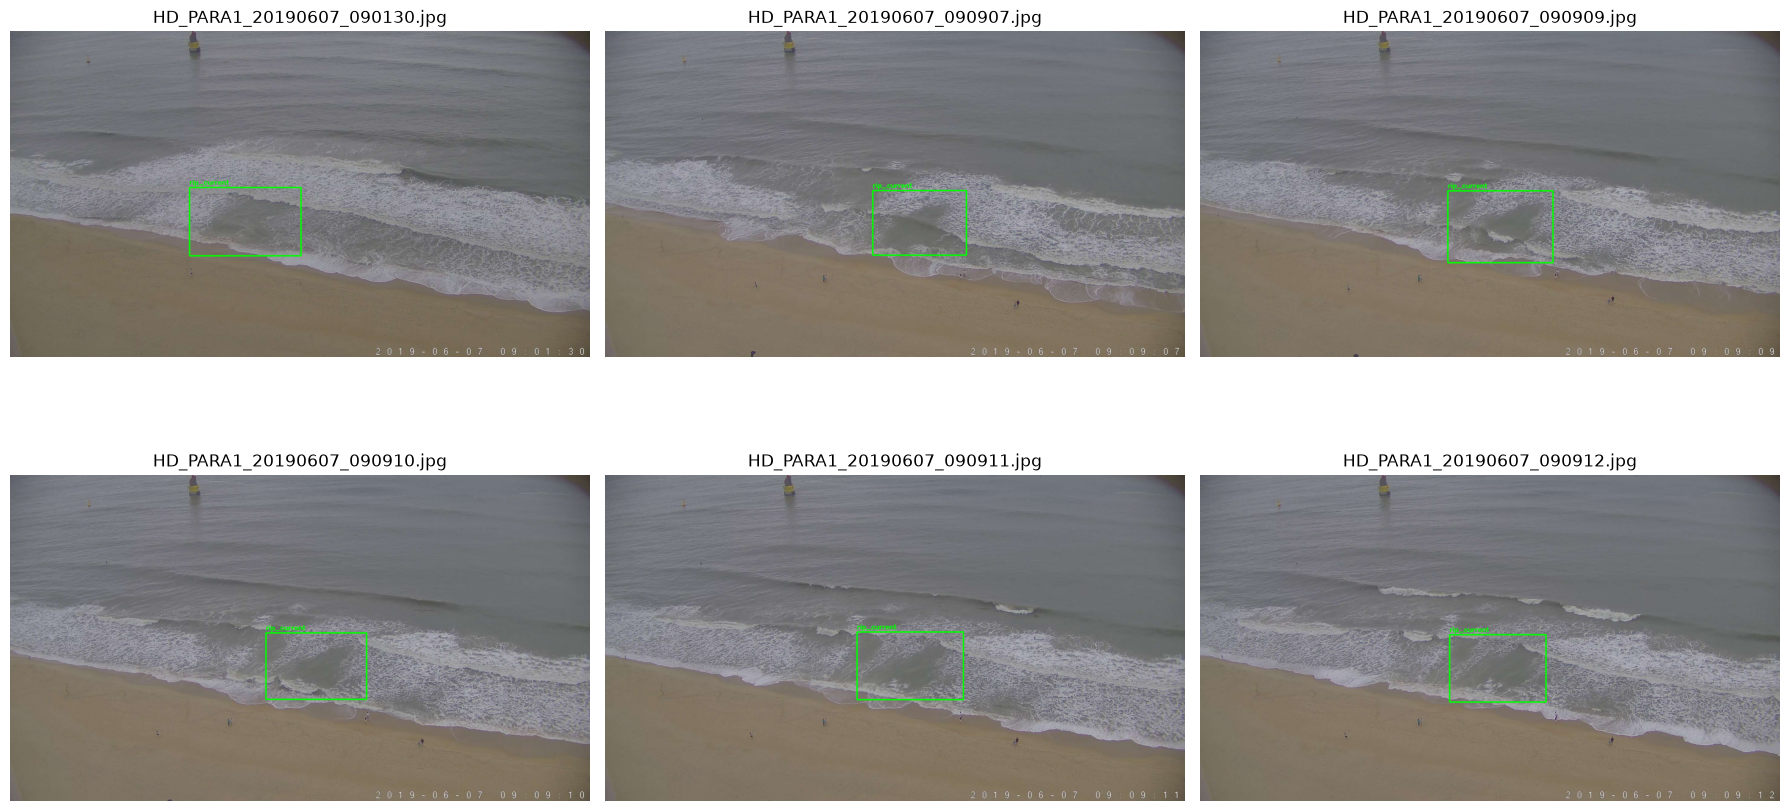

In [23]:
def draw_yolo_labels(image_path, label_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    h, w = image.shape[:2]

    if label_path.exists():
        lines = label_path.read_text(encoding="utf-8").strip().splitlines()

        for line in lines:
            if not line.strip():
                continue

            # xc, yc, bw, bh 픽셀값이 아님. 0~1 사이로 정규화된 좌표
            class_id, xc, yc, bw, bh = map(float, line.split())

            # YOLO 좌표를 실제 이미지 픽셀 좌표로 바꿈
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)
            #                   (좌측 상단) (우측 하단) (색상)      두께
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)
            # 글자 추가
            cv2.putText(
                image,
                CLASS_NAMES[int(class_id)],
                (x1, max(25, y1 - 8)),  # 좌측 상단 좌표 살짝 위
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Train image 전체 저장
train_images = sorted((TRAIN_DIR / "images").glob("*"))

positive_train_images = [
    p for p in train_images
    if (TRAIN_DIR / "labels" / f"{p.stem}.txt").exists()  # 이미지 파일명과 동일한 라벨 .txt 파일이 존재 하는지
    and (TRAIN_DIR / "labels" / f"{p.stem}.txt").stat().st_size > 0  # 파일 안에 글자가 써있는지 
]

# 최대 6장까지 보여주기
num_show = min(6, len(positive_train_images))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx in range(6):
    if idx >= num_show:
        axes[idx].axis("off")
        continue

    image_path = positive_train_images[idx]
    label_path = TRAIN_DIR / "labels" / f"{image_path.stem}.txt"

    axes[idx].imshow(draw_yolo_labels(image_path, label_path))
    axes[idx].set_title(image_path.name)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

# 5. YOLO 학습
- 사전 학습된 YOLO11s를 사용
- epochs=50, patience=10
- 검증 성능이 20 epochs동안 개선되지 않으면 Early Stopping으로 종료

In [26]:
model = YOLO(MODEL_NAME)

train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    project=str(PROJECT_DIR / "runs"),
    name="ripcurrent_yolo11s",
    exist_ok=True,
    seed=SEED,

    pretrained=True,
    plots=True,
    verbose=True,
)

New https://pypi.org/project/ultralytics/8.4.174 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.14.7 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\DEV\AIML\4_MULTIMODAL\data\ripcurrent\ripcurrent.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mi

# 6. 학습 수준 확인
- Precision: 이안류라고 예측한 것 중 실제 이안류인 비율
- Recall: 실제 이안류 중 모델이 찾아낸 비율
- mAP50: IoU 0.5 기준 객체 탐지 성능
- mAP50-95: 더 엄격한 여러 IoU 기준을 평균한 성능

> 단일 숫자 하나만 보지 말고 Precision, Recalll, mAP와 검증 이미지와 실제 박스 위치를 함께 확인해야 함

In [27]:
BEST_MODEL_PATH = (
    PROJECT_DIR
    / "runs"
    / "ripcurrent_yolo11s"
    / "weights"
    / "best.pt"
)

print("best.pt:", BEST_MODEL_PATH)
print("파일 존재:", BEST_MODEL_PATH.exists())

best_model = YOLO(str(BEST_MODEL_PATH))

metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True,
    verbose=False,
)

print("\n===== Validation 성능 =====")
print(f"Precision   : {metrics.box.mp:.4f}")
print(f"Recall      : {metrics.box.mr:.4f}")
print(f"mAP50       : {metrics.box.map50:.4f}")
print(f"mAP50-95    : {metrics.box.map:.4f}")

best.pt: C:\DEV\AIML\4_MULTIMODAL\data\ripcurrent\runs\ripcurrent_yolo11s\weights\best.pt
파일 존재: True
Ultralytics 8.4.171  Python-3.14.7 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 769.1232.4 MB/s, size: 88.3 KB)
val: Scanning C:\DEV\AIML\4_MULTIMODAL\data\ripcurrent\valid\labels.cache... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 4.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.4it/s 1.2s0.4s
                   all         30         30       0.72      0.433       0.45      0.111
Speed: 0.5ms preprocess, 19.3ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to C:\DEV\AIML\runs\detect\val

===== Validation 성능 =====
Precision   : 0.7201
Recall      : 0.4333
mAP50       : 0.4503
mAP50-95    : 0.1110


### Validation 결과에 대한 해석

- Precision: 0.7201
    - 모델이 이안류라고 예측한 결과 중 정답과 일치하는 비율이 적당히 높다.
    - True Positive가 많을 가능성이 있다.
    - False Positive(오탐) 가능성:
        - 육지를 이안류라고 판단
        - 일반 파도를 이안류라고 판단
        - 밝은 영역을 이안류라고 판단
- Recall: 0.4333
    - 실제 이안류 정답 중 모델이 찾아낸 비율이 약 43% 수준
    - Recall 낮으면 실제 이안류가 있는데도 박스를 만들지 못하는 False Nevgative(미탐)가 많다는 의미
    - 안전과 관련된 시스템에서는 미탐이 특히 중요
- mAP50: 0.4503
    - IoU 0.5를 기준으로 탐지 성능을 종합한 값
    - 예측 박스와 정답 박스가 얼마나 겹치는지를 측정
- mAP50-95: 0.1110
    - IoU 0.50 부터 0.95까지 더 엄격한 여러 기준에서 계산한 mAP의 평균
    - mAP50에 비해 mAP50-95가 크게 낮기 때문에, 단순히 이안류 주변을 대략적으로 찾는 것뿐 아니라 Bounding Box위치와 크기를 정밀하게 맞추는 능력도 많이 부족한 상태로 해석

### Underfitting과 Overfitting

1. Underfitting(과소적합)
    - 모델이 학습 데이터의 특징조차 충분히 배우지 못한 상태
    - 학습 시간이 부족함
    - 데이터 특징이 너무 부족함
    - 모델 용량이 부족함 (layer)
    - 입력 해상도가 너무 작아 필요한 특징이 손실됨

    > epoch, 모델 크기, 이미지 크기 등을 검토해볼 수 있음

2. Overfitting(과적합)
    - Train 데이터에서는 좋아지지만 Validation 데이터에서는 성능이 좋아지지 않거나 오히려 떨어지는 상태
    - 데이터가 너무 적음
    - 비슷한 연속 프레임이 지나치게 많음 (일반화 안됨)
    - 특정 CCTV 배경을 모델이 외움
    - 학습을 지나치게 오래 수행함

    > epoch을 더 늘리는 것은 오히려 문제를 악화시킬 수 있음 > 데이터를 늘려야 함

### Loss Curve 확인
- result.csv에는 epoch별 학습 결과가 저장
    - train/box_loss
    - val/box_loss
    - train/cls_loss
    - val/cls_loss
    - Precision
    - Recall
    - mAP50
    - mAP50-95

> Validation mAP가 더 이상 개선되지 않으면 과적합을 의심

In [30]:
import pandas as pd

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
9,10,125.868,2.00202,1.79203,1.86403,0.24370,0.36667,0.20425,0.06124,2.48039,2.73137,2.32250,0.001644,0.001644,0.001644
10,11,138.543,2.09081,1.80049,1.91093,0.15873,0.20000,0.14447,0.06345,2.16379,3.28771,1.91819,0.001604,0.001604,0.001604
11,12,150.873,1.85598,1.62862,1.75668,0.35479,0.13333,0.16546,0.03319,2.87460,3.31895,2.50874,0.001564,0.001564,0.001564
12,13,165.843,1.95226,1.73142,1.83071,0.17297,0.13333,0.05431,0.01141,2.99752,2.95858,2.87251,0.001525,0.001525,0.001525
13,14,179.143,1.86379,1.68394,1.80814,0.02477,0.16667,0.01759,0.00351,3.21435,3.89430,2.64998,0.001485,0.001485,0.001485
14,15,190.991,1.86789,1.62630,1.78362,0.24379,0.33333,0.23222,0.07755,2.55894,2.46650,2.10924,0.001446,0.001446,0.001446
15,16,203.114,1.76827,1.47537,1.72632,0.38275,0.40000,0.32401,0.11087,2.60378,2.44574,1.96741,0.001406,0.001406,0.001406
16,17,215.042,1.77034,1.46761,1.74637,0.20804,0.33333,0.13767,0.02603,2.65451,2.69724,2.24385,0.001366,0.001366,0.001366
17,18,226.806,1.67749,1.39231,1.68273,0.28300,0.43418,0.25469,0.05295,2.74573,2.35712,2.45141,0.001327,0.001327,0.001327
18,19,238.244,1.74693,1.49468,1.72503,0.42812,0.16667,0.22720,0.07056,2.44663,2.65392,2.66292,0.001287,0.001287,0.001287


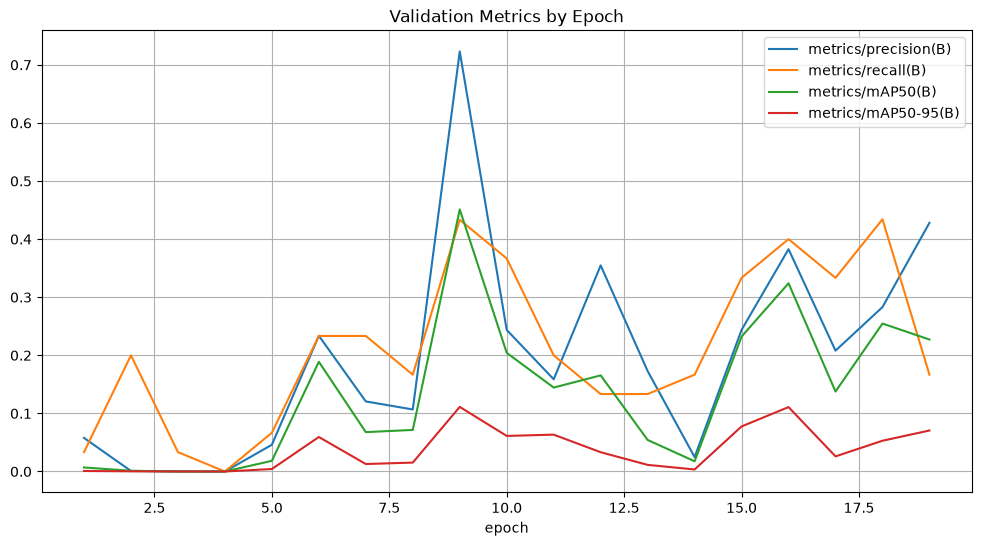

In [31]:
# 학습 과정 CSV 확인
RESULTS_CSV = (
    PROJECT_DIR
    / "runs"
    / "ripcurrent_yolo11s"
    / "results.csv"
)

if RESULTS_CSV.exists():
    history = pd.read_csv(RESULTS_CSV)
    history.columns = history.columns.str.strip()

    display(history.tail(10))

    metric_cols = [
        c for c in history.columns
        if "metrics/" in c
    ]

    if metric_cols:
        history.plot(
            x="epoch",
            y=metric_cols,
            figsize=(12, 6),
            grid=True
        )
        plt.title("Validation Metrics by Epoch")
        plt.show()
else:
    print("results.csv를 찾을 수 없습니다.")

# 7. Test 데이터로 최종 성능 확인

In [32]:
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True,
    verbose=False,
)

print("\n===== Test 성능 =====")
print(f"Precision   : {test_metrics.box.mp:.4f}")
print(f"Recall      : {test_metrics.box.mr:.4f}")
print(f"mAP50       : {test_metrics.box.map50:.4f}")
print(f"mAP50-95    : {test_metrics.box.map:.4f}")

Ultralytics 8.4.171  Python-3.14.7 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.71.2 ms, read: 155.162.2 MB/s, size: 105.6 KB)
val: Scanning C:\DEV\AIML\4_MULTIMODAL\data\ripcurrent\test\labels... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.4Kit/s 0.0s
val: New cache created: C:\DEV\AIML\4_MULTIMODAL\data\ripcurrent\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.7it/s 1.7s0.2s
                   all         60         60     0.0476       0.15     0.0156    0.00468
Speed: 0.3ms preprocess, 6.7ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to C:\DEV\AIML\runs\detect\val-2

===== Test 성능 =====
Precision   : 0.0476
Recall      : 0.1500
mAP50       : 0.0156
mAP50-95    : 0.0047


test_images 개수: 60


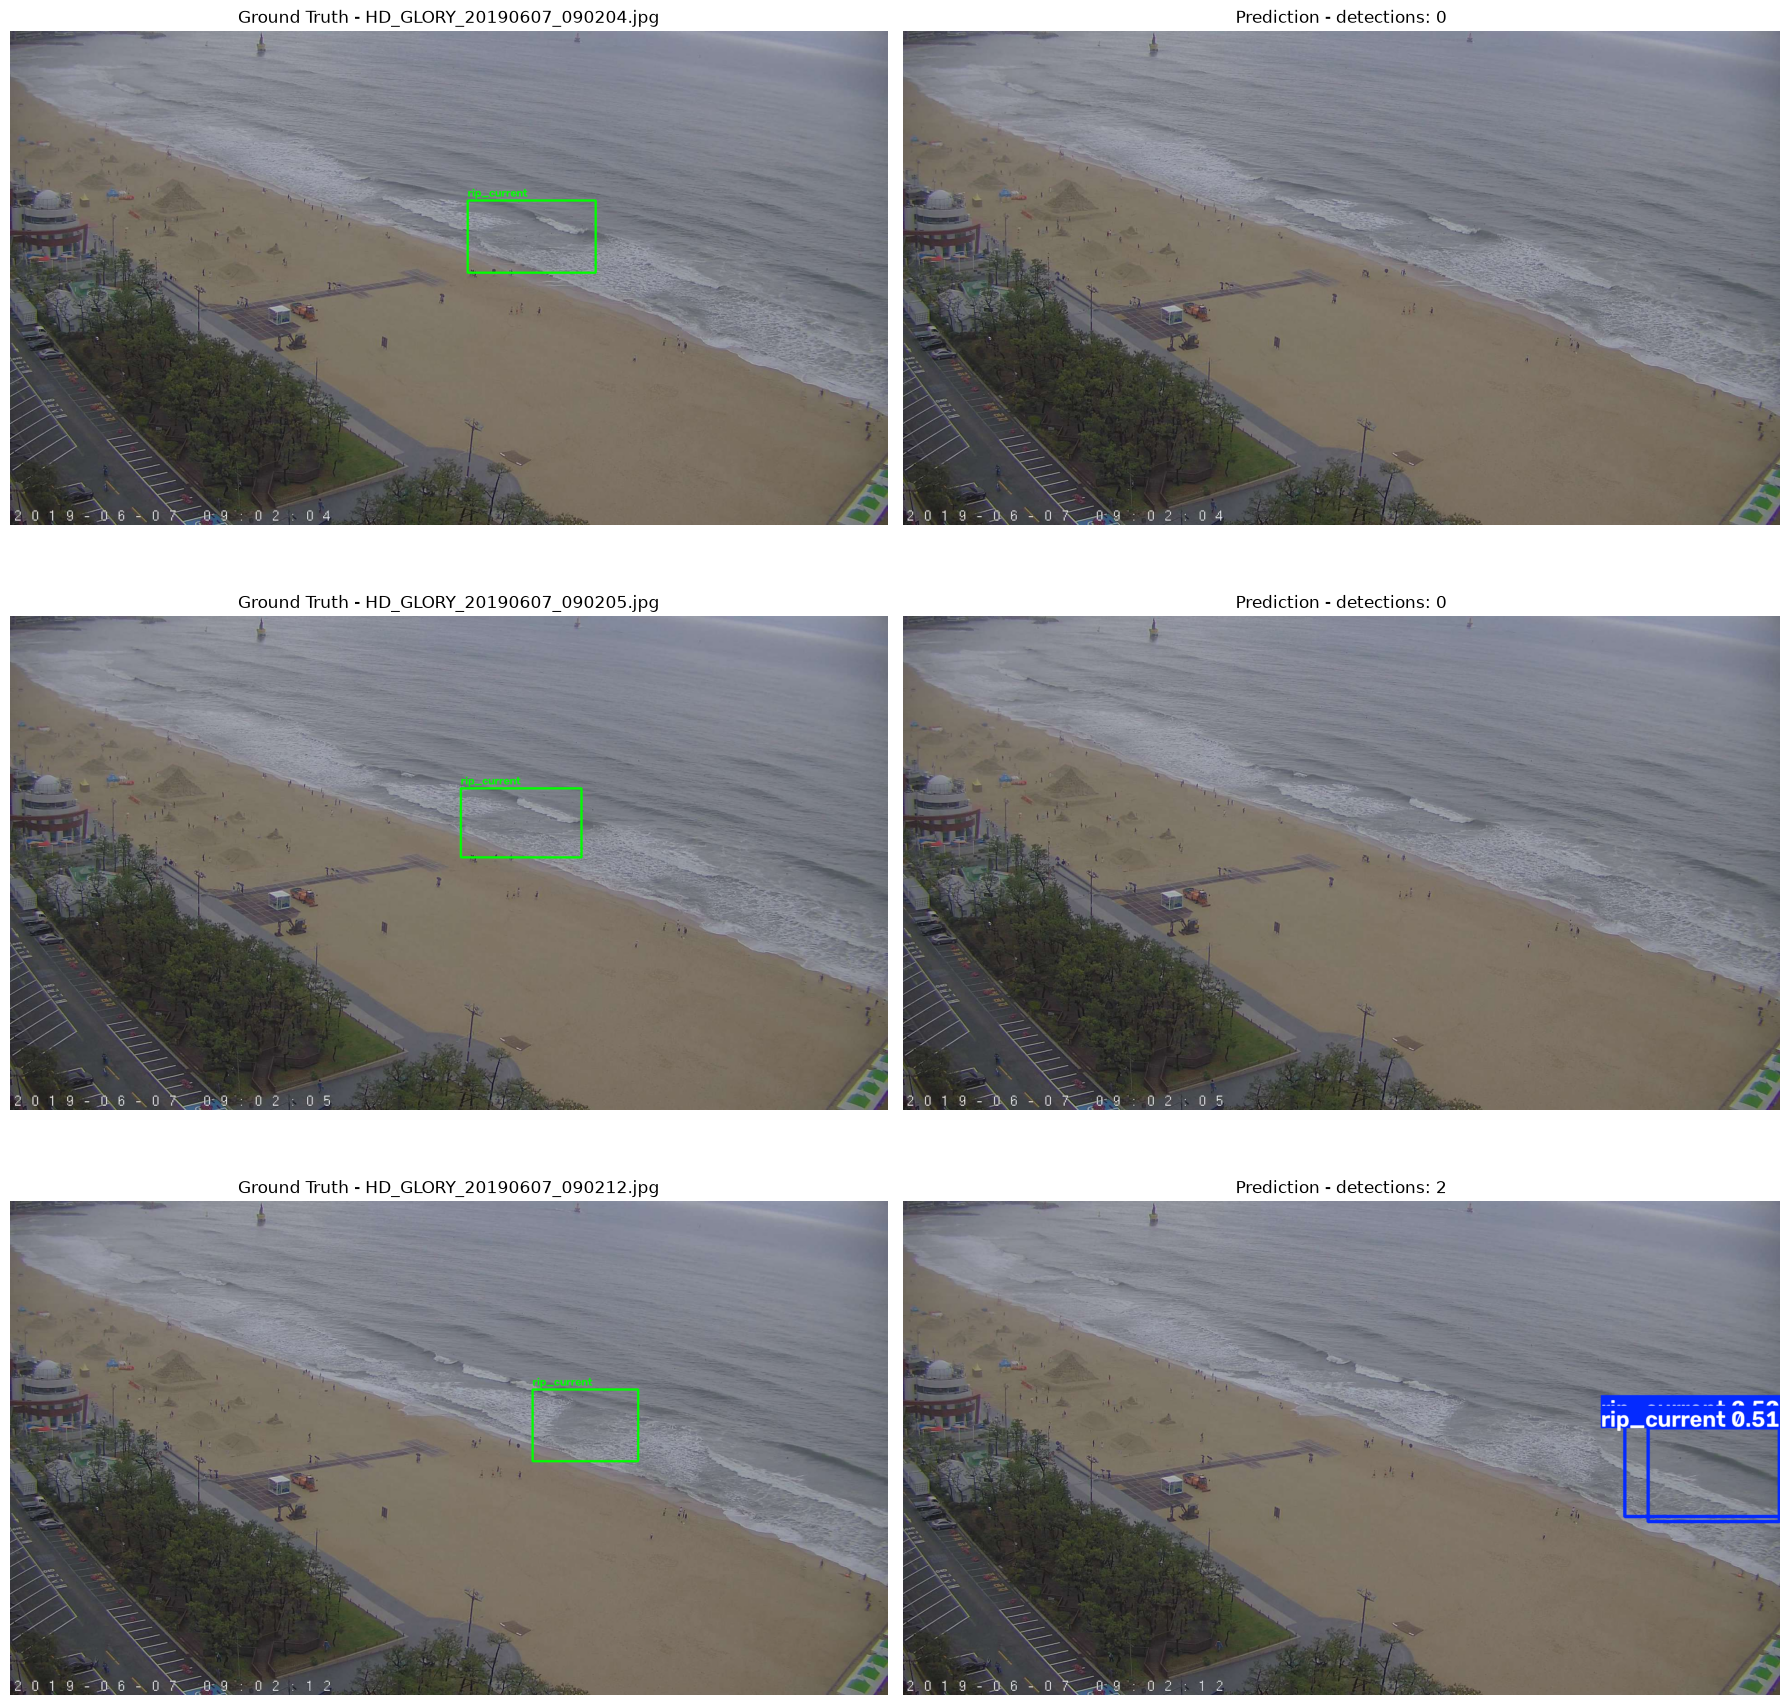

In [33]:
test_images = sorted([
    p for p in (TEST_DIR / "images").iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
])

print("test_images 개수:", len(test_images))

CONFIDENCE = 0.25
num_show = min(3, len(test_images))

fig, axes = plt.subplots(num_show, 2, figsize=(18, 6 * num_show))

if num_show == 1:
    axes = np.array([axes])

for idx in range(num_show):
    image_path = test_images[idx]
    label_path = TEST_DIR / "labels" / f"{image_path.stem}.txt"

    # 정답
    gt_rgb = draw_yolo_labels(image_path, label_path)

    # 예측
    result = best_model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE,
        iou=0.7,
        device=DEVICE,
        verbose=False,
    )[0]

    pred_bgr = result.plot()
    pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)

    axes[idx, 0].imshow(gt_rgb)
    axes[idx, 0].set_title(f"Ground Truth - {image_path.name}")
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(pred_rgb)
    axes[idx, 1].set_title(
        f"Prediction - detections: {len(result.boxes)}"
    )
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()

In [34]:
# 테스트 이미지별 confidence를 확인합니다.
for image_path in test_images[:10]:
    result = best_model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=0.01,   # 진단 목적으로만 낮게 설정
        iou=0.7,
        device=DEVICE,
        verbose=False,
    )[0]

    confidences = [
        round(float(box.conf.item()), 4)
        for box in result.boxes
    ]

    print(
        image_path.name,
        "| 탐지 수:",
        len(result.boxes),
        "| confidence:",
        confidences
    )

HD_GLORY_20190607_090204.jpg | 탐지 수: 12 | confidence: [0.1027, 0.0908, 0.0777, 0.0576, 0.0475, 0.0453, 0.0276, 0.0225, 0.0175, 0.0138, 0.0112, 0.0102]
HD_GLORY_20190607_090205.jpg | 탐지 수: 12 | confidence: [0.1093, 0.0457, 0.0441, 0.0362, 0.0303, 0.0148, 0.0145, 0.0142, 0.0139, 0.0133, 0.0118, 0.0115]
HD_GLORY_20190607_090212.jpg | 탐지 수: 16 | confidence: [0.5111, 0.5031, 0.1688, 0.1126, 0.0781, 0.0598, 0.027, 0.026, 0.0256, 0.0252, 0.0177, 0.0123, 0.0117, 0.0103, 0.0101, 0.0101]
HD_GLORY_20190607_090213.jpg | 탐지 수: 20 | confidence: [0.5135, 0.2352, 0.1913, 0.106, 0.0901, 0.0877, 0.0501, 0.0356, 0.0323, 0.0271, 0.02, 0.0196, 0.0169, 0.0135, 0.0124, 0.0117, 0.0109, 0.0105, 0.0104, 0.0102]
HD_GLORY_20190607_090214.jpg | 탐지 수: 19 | confidence: [0.2536, 0.1618, 0.1427, 0.1217, 0.0927, 0.0457, 0.0432, 0.0361, 0.0335, 0.0227, 0.0198, 0.0174, 0.0156, 0.0153, 0.0128, 0.012, 0.0119, 0.0119, 0.0103]
HD_GLORY_20190607_090215.jpg | 탐지 수: 16 | confidence: [0.2634, 0.1076, 0.0687, 0.0643, 0.0643, 0.04

# 8. 학습 상태 판단 기준
- 이안류 탐지에서 박스가 보인다고 좋은 모델이라고 판단하면 안됨
- 정답 박스는 정상인데 예측 박스가 게속 육지에 나타남 > 모델이 잘못된 특징을 학습하고 있을 가능성
- Recall이 매우 낮음 > 실제 이안류를 많이 놓침
- Precision이 매우 낮음 > 육지나 파도 등을 이안류라고 잘못 판단하는 경우가 많음
- train 성능만 좋아지고 validation 성능이 개선되지 않음 > 과적합 가능성
- mAP50은 높은데 mAP50-90가 매우 낮음 > 대략적인 위치는 맞지만 박스 위치가 정확하지 않을 가능성

> 먼저 위의 Validation/Test 지표와 정답/예측 비교 결과를 확인한 뒤 모델 크기, augmentation, image size 등을 추가로 조정함

# 9. 성능이 낮을 때 해결책
### 1. 라벨이 정확한지 확인
- 박스가 실제 이안류 위치를 감싸는가?
- 박스가 지나치게 크거나 작지 않은가?
- 이미지 해상도와 JSON 좌표가 일치하는지?
- 객체가 없는 이미지에는 빈 라벨이 들어가는지?
> 라벨이 틀리면 어떤 모델을 사용해도 올바른 결과를 학습할 수 없음

### 2. 데이터의 양보다 먼저 다양성을 확인
1. 더 많은 날짜
2. 더 다양한 시간대
3. 다른 CCTV 카메라
4. 다른 해수욕장
5. 서로 다른 파도 상태
6. 서로 다른 날씨와 조명
7. 다양한 크기와 위치의 이안류
8. 다양한 배경 이미지

> 비슷한 연속 프레임을 수천 장 추가하는 것보다 서로 다른 상황을 추가하는 것이 더 중요함

### 3. 연속 프레임의 중복 효과 줄이기
- 연속 프레임이 지나치게 많으면 특정 장면이 데이터셋에서 과도한 비중을 차지
- 전체 데이터를 구성할 때 필요에 따라 일정 시간으로 프레임을 샘플링하거나 영상 클립 단위로 데이터를 구성할 수 있음

### 4. Hard Negative를 수집
- 모델이 자주 틀리는 배경을 Hard Negative라고 함
- 예) 모델이 반복적으로 특정 파도, 해변 영역을 이안류라고 잘못 판단 > 그 장면을 객체가 없는 학습 데이터로 충분히 포함시키는 것이 도움이 될 수 있다.
- 모델 배포 후 발생한 오탐을 다시 데이터로 수집하여 재학습 과정을 반복하면 모델을 점진적으로 개선할 수 있음

### 5. epoch는 Loss Curve를 보고 결정
- 데이터가 부족한 상태에서 epoch만 계속 늘리면 과적합 가능성이 커짐
- Validation mAP가 계속 상승 중 > 추가 학습을 검토
- Validaiton mAP가 정체 > epoch 증가 효과가 제한적
- Train loss 감소하고 validation 성능 약화 > 과적합 가능성

### 6. 입력 해상도 검토
- 현재 IMAGE_SIZE = 640
- 이안류 특징이 화면에서 작거나 세밀하다면 더 큰 입력 해상도가 도움이 될 수도 있다.
- 해상도를 높이면 
    - CPU 메모리 사용량 증가
    - 학습 시간 증가
    - batch 감소 가능

### 7. 모델 크기 변경은 데이터 문제를 확인한 뒤
- 현재 YOLO11s 사용
- 더 큰 모델은 표현력이 증가할 수는 있지만, 데이터가 부족하면 오히려 특정 데이터에 과적합할 수도 있음
- 권장 순서: 데이터/라벨 확인 > 데이터 다양성 확보 > 학습 곡선 확인 > 모델 크기 조정

### 8. Confidence를 낮추는 것은 해결책이 아님
- conf=0.01은 낮은 confidence 후보까지 확인하기 위한 진단용 설정
- 실제 모델의 confidence가 0.03 ~ 0.10 수준인데 threshold만 0.01로 낮추면 탐지 박스는 늘어나지만 오탐도 크게 증가함

### 9. Detection이 문제 정의에 적합한지도 검토
- 현재 모델은 이안류 영역을 Bounding Box로 감싸는 Object Detection 방식
- 하지만 이안류는 형태가 불규칙하고 경계가 명확하지 않은 영역이므로, 실제 프로젝트 목적에 따라서는 Segmentation이 더 적합할 수도 있음